In [16]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
import sar_clip

In [ ]:
# ==========================================
# 1. 定义高分辨率 Grad-CAM 工具类 (适配 layer3)
# ==========================================
class GradCAM_ResNet_HiRes:
    def __init__(self, model, target_layer_name='layer3'):
        self.model = model
        self.feature_maps = None
        self.gradients = None
        
        # --- 关键修改点：Hook 更靠前的层 ---
        # 尝试 Hook model.visual.layer3
        try:
            # 根据传入名称获取层
            if target_layer_name == 'layer3':
                target_layer = model.visual.layer3
                print(f"✅ 成功 Hook 到高分辨率层: model.visual.layer3")
            elif target_layer_name == 'layer4':
                target_layer = model.visual.layer4
                print(f"✅ 成功 Hook 到标准层: model.visual.layer4")
            else:
                raise AttributeError

            target_layer.register_forward_hook(self.save_feature_maps)
            target_layer.register_backward_hook(self.save_gradients)
            
        except AttributeError:
            print(f"❌ 错误: 无法找到目标层，请确认模型架构是否为 ResNet 且包含 {target_layer_name}")

    def save_feature_maps(self, module, input, output):
        self.feature_maps = output 
        # 如果 Hook layer3，输出形状可能是 [1, 1024, 14, 14]

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0] 

    def generate_heatmap(self, image_input, text_input, target_text_index=0):
        self.model.zero_grad()
        image_features = self.model.encode_image(image_input)
        text_features = self.model.encode_text(text_input)

        image_features_norm = image_features / image_features.norm(dim=-1, keepdim=True)
        text_features_norm = text_features / text_features.norm(dim=-1, keepdim=True)
        logits = 100.0 * image_features_norm @ text_features_norm.T
        
        target_score = logits[0, target_text_index]
        target_score.backward()

        grads = self.gradients   
        fmaps = self.feature_maps 
        
        # 计算权重 (RN101 layer3 通常是 1024 通道)
        weights = torch.mean(grads, dim=(2, 3), keepdim=True) 
        
        # 加权求和
        cam = (weights * fmaps).sum(dim=1, keepdim=True) 
        cam = cam.squeeze() 

        # ReLU & 归一化
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-7)
        
        return cam.detach().cpu().numpy()

In [18]:
%cd /liuwenchu/code/detection/mmrotate/models/SARCLIP/

/liuwenchu/code/detection/mmrotate/models/SARCLIP


In [28]:
# ==========================================
# 2. 模型与数据准备 (基于你的代码)
# ==========================================
model_name = 'RN101' 
model_path = r'./sar_clip/model_configs/RN101/rn101_model.safetensors'
cache_dir= r"./sar_clip/model_configs/RN101"

# 加载模型
print("Loading model...")
model = sar_clip.create_model_with_args(model_name, pretrained=model_path)
model.eval() # 必须是 eval 模式
tokenizer = sar_clip.get_tokenizer(model_name, cache_dir=cache_dir)

# 加载图片
image_path = r"./0000745.jpg"
image_np = sar_clip.readtif(image_path)
# 预处理
image = torch.from_numpy(image_np).unsqueeze(0)
image = F.interpolate(image, size=(224, 224), mode='bicubic', align_corners=False)

# 🔥 关键：必须开启梯度，否则无法计算 GradCAM
image.requires_grad = True 

# 准备文本
text = [
    "an SAR image of car",
    "an SAR image of ship",
    "an SAR image of tank",
    "an SAR image of aircraft",
    "an SAR image of harbor",
    "an SAR image of bridge",
]
tokenized_text = tokenizer(text)

Loading model...


In [32]:
# ==========================================
# 3. 运行高分辨率 Grad-CAM
# ==========================================
# 初始化时指定 Hook 'layer3'
grad_cam_hires = GradCAM_ResNet_HiRes(model, target_layer_name='layer3')

# 初始化标准层作为对比
grad_cam_standard = GradCAM_ResNet_HiRes(model, target_layer_name='layer4')

target_idx = 1
print(f"正在生成热力图对比，关注文本: '{text[target_idx]}'")

# 生成两张热力图
heatmap_hires = grad_cam_hires.generate_heatmap(image, tokenized_text, target_text_index=target_idx)
heatmap_standard = grad_cam_standard.generate_heatmap(image, tokenized_text, target_text_index=target_idx)

✅ 成功 Hook 到高分辨率层: model.visual.layer3
✅ 成功 Hook 到标准层: model.visual.layer4
正在生成热力图对比，关注文本: 'an SAR image of ship'


Standard CAM raw size: (7, 7)
Hi-Res CAM raw size: (28, 28)


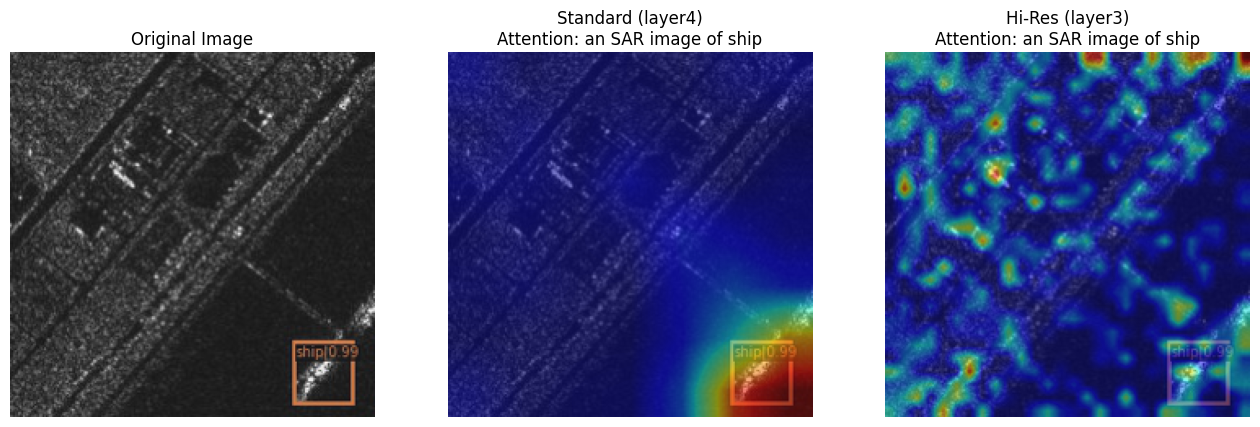


Predictions:
an SAR image of car            0.0048
an SAR image of ship           0.8541
an SAR image of tank           0.0202
an SAR image of aircraft       0.0009
an SAR image of harbor         0.1103
an SAR image of bridge         0.0096


In [33]:
# ==========================================
# 4. 绘图对比
# ==========================================
# 注意：如果你在 VS Code 交互式窗口运行，这里 plt.show() 没问题。
# 如果是远程脚本运行，请参考之前的建议使用 plt.savefig()

plt.figure(figsize=(16, 8))

# 1. 原图
plt.subplot(1, 3, 1)
img_show = image.detach().cpu().numpy()[0].transpose(1, 2, 0)
img_show = (img_show - img_show.min()) / (img_show.max() - img_show.min())
plt.imshow(img_show)
plt.title("Original Image")
plt.axis('off')

# 2. 标准层 (layer4, ~7x7)
plt.subplot(1, 3, 2)
# 检查原始尺寸以便理解差异
print(f"Standard CAM raw size: {heatmap_standard.shape}")
heatmap_std_resized = cv2.resize(heatmap_standard, (224, 224))
plt.imshow(img_show)
plt.imshow(heatmap_std_resized, cmap='jet', alpha=0.5) 
plt.title(f"Standard (layer4)\nAttention: {text[target_idx]}")
plt.axis('off')

# 3. 高分辨率层 (layer3, ~14x14)
plt.subplot(1, 3, 3)
# 检查原始尺寸
print(f"Hi-Res CAM raw size: {heatmap_hires.shape}")
heatmap_hires_resized = cv2.resize(heatmap_hires, (224, 224))
plt.imshow(img_show)
plt.imshow(heatmap_hires_resized, cmap='jet', alpha=0.5) 
plt.title(f"Hi-Res (layer3)\nAttention: {text[target_idx]}")
plt.axis('off')

plt.show()

# 打印预测概率作为参考
with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(tokenized_text)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)
    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

print("\nPredictions:")
for label, prob in zip(text, text_probs[0].cpu().numpy()):
    print(f"{label:<30} {prob:.4f}")